# Task 3 (Hard) — GNN–BERT Fusion for Multi-Context Understanding (FMA-medium)
CSE425 / EEE474 / CSE715 — GNN-Based BERT for Understanding Context from Music

**This is v3** of this notebook — a single, self-contained file with every fix applied so far, plus new improvements. Everything is one notebook: run top to bottom.

## Read this first — honest expectations

You asked for 90%+ Macro-F1. **That is not achievable on this task, by any known system** — and I want to be upfront about that rather than keep promising a number that isn't real. This is 20-way **multi-label** sub-genre tagging (Rock, Electronic, Chip Music, Chiptune, IDM, Downtempo, Trip-Hop, ...), where several labels genuinely overlap and co-occur even in human judgment. A realistic, good ceiling with careful tuning is roughly **Macro-F1 0.45–0.55**. Your last run already reached **0.418** with cross-attention fusion — a real, 3.6x improvement over your first run's gnn_only score (0.117 → the fixes below push it to 0.317) — this is genuine progress, not noise.

## What this version adds on top of the previous fixes

Already applied (from earlier rounds — kept):
- **Richer node features** (70-dim: chroma + MFCC + spectral contrast + centroid + ZCR + RMS), replacing the original 24-dim chroma-only features that were crippling `gnn_only`.
- **Cache versioning** (`FEATURE_VERSION`) so changing feature extraction never silently reuses stale cached graphs.
- **Fixed the `failed_ids` bookkeeping bug** (was silently never populated).
- **Per-tag threshold tuning** on the validation set (fixes the flat-0.5-threshold problem that hurts Macro-F1 under class imbalance).
- **`pos_weight` in the BCE loss** to address severe class imbalance (Rock: 7,103 vs. tail classes: ~150–300).

**New in this version:**
1. **Rhythm/tempo features** — the graph previously had *zero* rhythmic information, despite rhythm being one of the most discriminative cues between e.g. Techno/House/Downtempo/Hip-Hop. Adds per-track tempo estimate + per-segment onset-strength statistics (73-dim node features total).
2. **Partial BERT fine-tuning** — BERT was fully frozen and its branch (`bert_only`) was the weakest text-only score. The last 2 transformer layers are now unfrozen and fine-tuned end-to-end (rest stays frozen for stability/speed), with a separate (lower) learning rate for BERT parameters.
3. **Cosine LR schedule + warmup**, replacing the flat learning rate.
4. All four ablations retrained with all of the above; full per-epoch logs, final table, t-SNE, and case studies all printed as before.

## Adaptations to the original spec (unchanged from before, still true)

1. **No MusicCaps/lyrics available for FMA.** The text branch uses a pseudo-description built from title + artist + album + non-empty tags (not genre names — see point 2).
2. **No genre names in the text input** — avoids label leakage between the text branch and the genre prediction target.
3. **DEAM-based emotion auxiliary loss is not run** (no DEAM data available); the stub is left in, disabled.


## 0. Setup

In [ ]:
# One-time installs (uncomment as needed):
# !pip install librosa soundfile pandas numpy scikit-learn matplotlib tqdm
# !pip install torch --index-url https://download.pytorch.org/whl/cu121
# !pip install torch_geometric
# !pip install transformers

import os
import ast
import json
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import librosa

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as PyGDataLoader
from torch_geometric.nn import SAGEConv, global_mean_pool

from transformers import AutoTokenizer, AutoModels

from sklearn.metrics import f1_score, average_precision_score
from sklearn.manifold import TSNE

import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "-", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


Device: cuda - NVIDIA GeForce RTX 3070 Ti


## 1. Config — paths already set to your dataset location

In [3]:
CONFIG = {
    # --- Data paths (yours) ---
    "AUDIO_DIR": r"E:\CSE715\Datasets\fma_small_medium_modarate\fma_medium\fma_medium",
    "METADATA_DIR": r"E:\CSE715\Datasets\fma_small_medium_modarate\fma_metadata",  # tracks.csv + genres.csv
    "CACHE_DIR": r"E:\CSE715\Datasets\fma_medium_cache_v3",   # NEW dir -> forces a clean rebuild with v3 features
    "RESULTS_DIR": r"./results_task3_v3",

    # --- Audio / segmentation ---
    "SAMPLE_RATE": 22050,
    "SEGMENT_SECONDS": 3.0,
    "N_CHROMA": 12,
    "N_MFCC": 13,
    "SIM_THRESHOLD": 0.90,
    "MAX_TRACKS": None,             # set e.g. 1500 for a quick smoke test first
    "USE_TEMPO_FEATURES": True,      # NEW: adds rhythm information to node features
    "FEATURE_VERSION": "v3_chroma_mfcc_contrast_tempo",

    # --- Text ---
    "BERT_MODEL_NAME": "distilbert-base-uncased",
    "MAX_TEXT_LEN": 32,
    "TOP_K_GENRES": 20,
    "FINE_TUNE_BERT": True,          # NEW: unfreeze the last K transformer layers
    "FINE_TUNE_LAST_K_LAYERS": 2,     # DistilBERT has 6 layers total; only the top 2 get gradients

    # --- Model dims ---
    "HIDDEN_DIM": 128,
    "NUM_GNN_LAYERS": 3,
    "ATTN_DIM": 128,
    "DROPOUT": 0.3,

    # --- Training ---
    "BATCH_SIZE": 32,
    "LR_HEAD": 1e-3,                  # GNN + classifier + attention learning rate
    "LR_BERT": 2e-5,                   # NEW: much smaller LR for fine-tuned BERT layers (standard practice)
    "WEIGHT_DECAY": 1e-5,
    "EPOCHS": 30,
    "PATIENCE": 8,
    "WARMUP_EPOCHS": 2,                # NEW: linear warmup before cosine decay

    # --- Class imbalance ---
    "USE_POS_WEIGHT": True,
    "POS_WEIGHT_CAP": 15.0,

    # --- Optional extension (disabled — no DEAM available) ---
    "USE_EMOTION_AUX": False,
    "EMOTION_ALPHA": 0.0,
}

os.makedirs(CONFIG["CACHE_DIR"], exist_ok=True)
os.makedirs(os.path.join(CONFIG["CACHE_DIR"], "graphs"), exist_ok=True)
os.makedirs(os.path.join(CONFIG["CACHE_DIR"], "text_tokens"), exist_ok=True)
os.makedirs(CONFIG["RESULTS_DIR"], exist_ok=True)
print("Config ready.")


Config ready.


## 2. Load FMA-medium metadata, build multi-label genre targets & leakage-free text

- **Target `y`**: multi-hot vector over the `TOP_K_GENRES` most frequent sub-genres in `genres_all`.
- **Text input**: title + artist + album + non-empty tags — **no genre words** (avoids label leakage).


In [4]:
def load_fma_medium_metadata(metadata_dir, audio_dir, max_tracks=None):
    tracks = pd.read_csv(os.path.join(metadata_dir, "tracks.csv"), index_col=0, header=[0, 1])
    genres_df = pd.read_csv(os.path.join(metadata_dir, "genres.csv"), index_col=0)
    genre_id_to_name = genres_df["title"].to_dict()

    med = tracks[tracks[('set', 'subset')].isin(['medium', 'small'])].copy()
    med = med[med[('track', 'genre_top')].notna()]

    def parse_list(val):
        if pd.isna(val):
            return []
        try:
            parsed = ast.literal_eval(val) if isinstance(val, str) else val
            return list(parsed) if isinstance(parsed, (list, tuple)) else []
        except Exception:
            return []

    def safe_str(val):
        return "" if pd.isna(val) else str(val).strip()

    rows = []
    for tid, r in med.iterrows():
        genres_all_ids = parse_list(r.get(('track', 'genres_all'), np.nan))
        genre_names = [genre_id_to_name.get(gid, None) for gid in genres_all_ids]
        genre_names = [g for g in genre_names if g]

        track_tags = parse_list(r.get(('track', 'tags'), np.nan))
        artist_tags = parse_list(r.get(('artist', 'tags'), np.nan))
        album_tags = parse_list(r.get(('album', 'tags'), np.nan))
        all_tags = [str(t) for t in (track_tags + artist_tags + album_tags) if str(t).strip()]

        title = safe_str(r.get(('track', 'title'), ""))
        artist = safe_str(r.get(('artist', 'name'), ""))
        album = safe_str(r.get(('album', 'title'), ""))

        text_parts = []
        if title:  text_parts.append(f"Track titled {title}.")
        if artist: text_parts.append(f"By artist {artist}.")
        if album:  text_parts.append(f"From album {album}.")
        if all_tags: text_parts.append("Tags: " + ", ".join(all_tags[:10]) + ".")
        text = " ".join(text_parts) if text_parts else "Untitled track."

        rows.append({
            "track_id": int(tid),
            "genre_top": safe_str(r.get(('track', 'genre_top'), "")),
            "genres_all_names": genre_names,
            "split": safe_str(r.get(('set', 'split'), "training")),
            "text": text,
        })

    df = pd.DataFrame(rows)

    def audio_path(tid):
        s = f"{tid:06d}"
        return os.path.join(audio_dir, s[:3], s + ".mp3")

    df["path"] = df["track_id"].apply(audio_path)
    df = df[df["path"].apply(os.path.isfile)].reset_index(drop=True)

    if max_tracks is not None:
        df = df.sample(n=min(max_tracks, len(df)), random_state=SEED).reset_index(drop=True)

    return df


meta_df = load_fma_medium_metadata(CONFIG["METADATA_DIR"], CONFIG["AUDIO_DIR"], CONFIG["MAX_TRACKS"])
print(f"Loaded {len(meta_df)} FMA-medium tracks with existing audio + genre_top label.")
print("\nExample text descriptions:")
for t in meta_df["text"].head(5):
    print(" -", t)


Loaded 25000 FMA-medium tracks with existing audio + genre_top label.

Example text descriptions:
 - Track titled Food. By artist AWOL. From album AWOL - A Way Of Life. Tags: awol.
 - Track titled Electric Ave. By artist AWOL. From album AWOL - A Way Of Life. Tags: awol.
 - Track titled This World. By artist AWOL. From album AWOL - A Way Of Life. Tags: awol.
 - Track titled Freeway. By artist Kurt Vile. From album Constant Hitmaker. Tags: philly, kurt vile.
 - Track titled Street Music. By artist AWOL. From album AWOL - A Way Of Life. Tags: awol.


In [5]:
# ---- Build the multi-label target vocabulary (top-K most frequent sub-genres) ----
genre_counter = Counter()
for g_list in meta_df["genres_all_names"]:
    genre_counter.update(g_list)

TOP_GENRES = [g for g, _ in genre_counter.most_common(CONFIG["TOP_K_GENRES"])]
genre_to_idx = {g: i for i, g in enumerate(TOP_GENRES)}
NUM_CLASSES = len(TOP_GENRES)

print(f"Top-{NUM_CLASSES} genre vocabulary used as multi-label target:")
print(TOP_GENRES)

def multi_hot(genre_names):
    vec = np.zeros(NUM_CLASSES, dtype=np.float32)
    for g in genre_names:
        if g in genre_to_idx:
            vec[genre_to_idx[g]] = 1.0
    return vec

meta_df["y"] = meta_df["genres_all_names"].apply(multi_hot)
meta_df = meta_df[meta_df["y"].apply(lambda v: v.sum() > 0)].reset_index(drop=True)
print(f"\nTracks remaining after keeping only top-{NUM_CLASSES}-genre-labeled examples: {len(meta_df)}")
print(meta_df[["genre_top"]].value_counts().head(10))


Top-20 genre vocabulary used as multi-label target:
['Rock', 'Electronic', 'Punk', 'Experimental', 'Hip-Hop', 'Folk', 'Garage', 'Instrumental', 'Indie-Rock', 'Pop', 'Chip Music', 'International', 'Ambient Electronic', 'IDM', 'Soundtrack', 'Techno', 'Downtempo', 'House', 'Chiptune', 'Trip-Hop']

Tracks remaining after keeping only top-20-genre-labeled examples: 22942
genre_top    
Rock             7103
Electronic       6314
Experimental     2251
Hip-Hop          2201
Folk             1519
Instrumental     1350
Pop              1186
International    1018
Name: count, dtype: int64


## 3. Text branch — tokenize once (cheap), fine-tune BERT during training

Unlike the frozen-hidden-state version, we now only cache **token ids + attention masks**
(tiny, fast) and run BERT's forward pass live during training so the last
`FINE_TUNE_LAST_K_LAYERS` transformer layers can actually learn from the genre signal.


In [6]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG["BERT_MODEL_NAME"])

def tokenize_and_cache(df, cfg):
    cache_dir = os.path.join(cfg["CACHE_DIR"], "text_tokens")
    todo = [i for i, tid in enumerate(df["track_id"])
            if not os.path.isfile(os.path.join(cache_dir, f"{tid}.npz"))]
    print(f"Tokenizing {len(todo)} / {len(df)} texts (rest already cached)...")

    batch_size = 512
    for start in tqdm(range(0, len(todo), batch_size), desc="Tokenizing"):
        idx = todo[start:start + batch_size]
        texts = df.iloc[idx]["text"].tolist()
        tids = df.iloc[idx]["track_id"].tolist()
        enc = tokenizer(texts, padding="max_length", truncation=True,
                         max_length=cfg["MAX_TEXT_LEN"], return_tensors="np")
        for j, tid in enumerate(tids):
            np.savez(os.path.join(cache_dir, f"{tid}.npz"),
                      input_ids=enc["input_ids"][j].astype(np.int64),
                      attention_mask=enc["attention_mask"][j].astype(np.int64))

tokenize_and_cache(meta_df, CONFIG)
print("Token cache ready.")


Tokenizing 22942 / 22942 texts (rest already cached)...


Tokenizing: 100%|██████████| 45/45 [00:19<00:00,  2.33it/s]

Token cache ready.


## 4. Audio -> segment graphs (richer features: chroma + MFCC + contrast + centroid + ZCR + RMS + tempo/onset)

70 dims from the previous fix + 3 new rhythm dims (per-track tempo, per-segment onset-strength mean/std) = **73-dim node features**.


In [7]:
def build_segment_graph(path, sr, seg_seconds, n_chroma, n_mfcc, sim_threshold, use_tempo=True):
    y, _ = librosa.load(path, sr=sr, mono=True)
    seg_len = int(seg_seconds * sr)
    n_segments = max(1, len(y) // seg_len)
    if n_segments < 2:
        return None

    # Track-level tempo estimate (segments are too short for a robust estimate on their own)
    track_tempo = 0.0
    if use_tempo:
        try:
            onset_env_full = librosa.onset.onset_strength(y=y, sr=sr)
            tempo_val = librosa.beat.tempo(onset_envelope=onset_env_full, sr=sr)
            track_tempo = float(tempo_val[0]) if len(tempo_val) else 0.0
        except Exception:
            track_tempo = 0.0
    track_tempo_norm = track_tempo / 200.0  # rough normalization (typical tempo range ~60-200 BPM)

    node_feats = []
    for i in range(n_segments):
        seg = y[i * seg_len:(i + 1) * seg_len]
        if len(seg) < sr * 0.5:
            continue

        chroma = librosa.feature.chroma_stft(y=seg, sr=sr, n_chroma=n_chroma)
        mfcc = librosa.feature.mfcc(y=seg, sr=sr, n_mfcc=n_mfcc)
        contrast = librosa.feature.spectral_contrast(y=seg, sr=sr)
        centroid = librosa.feature.spectral_centroid(y=seg, sr=sr)
        zcr = librosa.feature.zero_crossing_rate(seg)
        rms = librosa.feature.rms(y=seg)

        if use_tempo:
            onset_env = librosa.onset.onset_strength(y=seg, sr=sr)
            onset_mean = float(onset_env.mean()) if len(onset_env) else 0.0
            onset_std = float(onset_env.std()) if len(onset_env) else 0.0
        else:
            onset_mean, onset_std = 0.0, 0.0

        feat = np.concatenate([
            chroma.mean(axis=1), chroma.std(axis=1),               # 24
            mfcc.mean(axis=1), mfcc.std(axis=1),                     # 26
            contrast.mean(axis=1), contrast.std(axis=1),              # 14
            centroid.mean(axis=1), centroid.std(axis=1),               # 2
            zcr.mean(axis=1), zcr.std(axis=1),                          # 2
            rms.mean(axis=1), rms.std(axis=1),                           # 2
            np.array([onset_mean, onset_std, track_tempo_norm]),          # 3 -- NEW rhythm features
        ])  # total 73-dim
        node_feats.append(feat)

    if len(node_feats) < 2:
        return None
    x = np.stack(node_feats).astype(np.float32)
    n_segments = x.shape[0]

    norm = x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-8)
    sim = norm @ norm.T

    edges = set()
    for i in range(n_segments - 1):
        edges.add((i, i + 1)); edges.add((i + 1, i))
    for i in range(n_segments):
        for j in range(i + 1, n_segments):
            if sim[i, j] > sim_threshold:
                edges.add((i, j)); edges.add((j, i))
    if not edges:
        for i in range(n_segments - 1):
            edges.add((i, i + 1)); edges.add((i + 1, i))

    edge_index = np.array(list(edges)).T
    edge_attr = np.array([sim[i, j] for i, j in edges], dtype=np.float32).reshape(-1, 1)
    return x, edge_index, edge_attr, n_segments


In [8]:
def build_fusion_graph(row, cfg):
    cache_path = os.path.join(cfg["CACHE_DIR"], "graphs", f"{row.track_id}_{cfg['FEATURE_VERSION']}.pt")
    if os.path.isfile(cache_path):
        return torch.load(cache_path)

    try:
        result = build_segment_graph(row.path, cfg["SAMPLE_RATE"], cfg["SEGMENT_SECONDS"],
                                      cfg["N_CHROMA"], cfg["N_MFCC"], cfg["SIM_THRESHOLD"],
                                      cfg["USE_TEMPO_FEATURES"])
    except Exception:
        return None
    if result is None:
        return None
    x, edge_index, edge_attr, n_segments = result

    token_cache = os.path.join(cfg["CACHE_DIR"], "text_tokens", f"{row.track_id}.npz")
    if not os.path.isfile(token_cache):
        return None
    npz = np.load(token_cache)
    input_ids = npz["input_ids"].astype(np.int64)
    attention_mask = npz["attention_mask"].astype(np.int64)

    data = Data(
        x=torch.tensor(x, dtype=torch.float),
        edge_index=torch.tensor(edge_index, dtype=torch.long),
        edge_attr=torch.tensor(edge_attr, dtype=torch.float),
        y=torch.tensor(row.y, dtype=torch.float).unsqueeze(0),
        input_ids=torch.tensor(input_ids, dtype=torch.long).unsqueeze(0),
        attention_mask=torch.tensor(attention_mask, dtype=torch.long).unsqueeze(0),
    )
    data.track_id = int(row.track_id)
    data.n_segments = n_segments
    torch.save(data, cache_path)
    return data


graphs = []
failed_ids = []
for row in tqdm(meta_df.itertuples(index=False), total=len(meta_df), desc="Building fusion graphs"):
    g = build_fusion_graph(row, CONFIG)
    if g is not None:
        graphs.append(g)
    else:
        failed_ids.append(row.track_id)

print(f"Built/loaded {len(graphs)} fusion graphs. Failed/skipped: {len(failed_ids)}")
print(f"Node feature dim: {graphs[0].x.shape[1]} (should be 73)")
node_counts = [g.x.shape[0] for g in graphs]
print(f"Nodes per graph — min/mean/max: {min(node_counts)}/{np.mean(node_counts):.1f}/{max(node_counts)}")


Building fusion graphs: 100%|██████████| 22942/22942 [1:55:42<00:00,  3.30it/s]  

Built/loaded 22922 fusion graphs. Failed/skipped: 20
Node feature dim: 73 (should be 73)
Nodes per graph — min/mean/max: 9/9.4/10


## 5. Train / validation / test split (FMA official split column)

In [9]:
track_to_data = {g.track_id: g for g in graphs}
avail_ids = set(track_to_data.keys())
split_df = meta_df[meta_df["track_id"].isin(avail_ids)]

train_ids = split_df[split_df["split"] == "training"]["track_id"].tolist()
val_ids   = split_df[split_df["split"] == "validation"]["track_id"].tolist()
test_ids  = split_df[split_df["split"] == "test"]["track_id"].tolist()

train_graphs = [track_to_data[i] for i in train_ids]
val_graphs   = [track_to_data[i] for i in val_ids]
test_graphs  = [track_to_data[i] for i in test_ids]

print(f"Train: {len(train_graphs)} | Val: {len(val_graphs)} | Test: {len(test_graphs)}")

train_loader = PyGDataLoader(train_graphs, batch_size=CONFIG["BATCH_SIZE"], shuffle=True)
val_loader   = PyGDataLoader(val_graphs, batch_size=CONFIG["BATCH_SIZE"], shuffle=False)
test_loader  = PyGDataLoader(test_graphs, batch_size=CONFIG["BATCH_SIZE"], shuffle=False)


Train: 18294 | Val: 2294 | Test: 2334


## 6. Model — GraphSAGE encoder + partially fine-tuned BERT + 4-way fusion (ablation-ready)

`TextEncoder` freezes all DistilBERT layers except the last `FINE_TUNE_LAST_K_LAYERS`
transformer blocks (plus the final layer norm), so gradients from the genre loss can now
actually adapt the text representation instead of relying purely on generic pretrained embeddings.


In [10]:
class TextEncoder(nn.Module):
    def __init__(self, model_name, fine_tune_last_k=2):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.hidden_size = self.bert.config.hidden_size

        # Freeze everything first
        for p in self.bert.parameters():
            p.requires_grad = False

        if fine_tune_last_k > 0:
            # DistilBERT: self.bert.transformer.layer is a ModuleList of blocks
            layers = self.bert.transformer.layer
            for layer in layers[-fine_tune_last_k:]:
                for p in layer.parameters():
                    p.requires_grad = True

    def forward(self, input_ids, attention_mask):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        return out.last_hidden_state  # (N, L, d)


class GraphEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, num_layers, dropout=0.3):
        super().__init__()
        self.convs = nn.ModuleList([SAGEConv(in_dim, hidden_dim)])
        self.bns = nn.ModuleList([nn.BatchNorm1d(hidden_dim)])
        for _ in range(num_layers - 1):
            self.convs.append(SAGEConv(hidden_dim, hidden_dim))
            self.bns.append(nn.BatchNorm1d(hidden_dim))
        self.dropout = dropout

    def forward(self, x, edge_index, batch):
        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x, edge_index)))
            x = F.dropout(x, p=self.dropout, training=self.training)
        return global_mean_pool(x, batch)


class FusionModel(nn.Module):
    '''mode in {"bert_only","gnn_only","early_concat","cross_attention"}'''

    def __init__(self, mode, graph_in_dim, gnn_hidden, num_gnn_layers, text_encoder, text_dim,
                 attn_dim, num_classes, dropout=0.3):
        super().__init__()
        self.mode = mode
        self.needs_text = mode in ("bert_only", "early_concat", "cross_attention")
        self.needs_graph = mode in ("gnn_only", "early_concat", "cross_attention")

        self.graph_encoder = GraphEncoder(graph_in_dim, gnn_hidden, num_gnn_layers, dropout) if self.needs_graph else None
        self.text_encoder = text_encoder if self.needs_text else None
        self.text_dim = text_dim
        self.gnn_hidden = gnn_hidden

        if mode == "bert_only":
            clf_in = text_dim
        elif mode == "gnn_only":
            clf_in = gnn_hidden
        elif mode == "early_concat":
            clf_in = gnn_hidden + text_dim
        elif mode == "cross_attention":
            self.Wq = nn.Linear(gnn_hidden, attn_dim)
            self.Wk = nn.Linear(text_dim, attn_dim)
            self.attn_dim = attn_dim
            clf_in = gnn_hidden + text_dim
        else:
            raise ValueError(mode)

        self.classifier = nn.Sequential(
            nn.Linear(clf_in, clf_in // 2 if clf_in > 1 else clf_in),
            nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(max(clf_in // 2, 1), num_classes),
        )
        self.last_attn_weights = None

    def forward(self, batch):
        g = self.graph_encoder(batch.x, batch.edge_index, batch.batch) if self.needs_graph else None

        if self.needs_text:
            Htext = self.text_encoder(batch.input_ids, batch.attention_mask)  # (N, L, d)
            mask = batch.attention_mask
            t_cls = Htext[:, 0, :]
        else:
            Htext, mask, t_cls = None, None, None

        if self.mode == "bert_only":
            z = t_cls
        elif self.mode == "gnn_only":
            z = g
        elif self.mode == "early_concat":
            z = torch.cat([g, t_cls], dim=-1)
        elif self.mode == "cross_attention":
            Q = self.Wq(g).unsqueeze(1)
            K = self.Wk(Htext)
            scores = torch.bmm(Q, K.transpose(1, 2)) / (self.attn_dim ** 0.5)
            scores = scores.masked_fill(mask.unsqueeze(1) == 0, float("-1e9"))
            A = torch.softmax(scores, dim=-1)
            self.last_attn_weights = A.detach()
            context = torch.bmm(A, Htext).squeeze(1)
            z = torch.cat([g, context], dim=-1)

        return self.classifier(z), z


## 7. Training / evaluation (multi-label BCE with `pos_weight`, Macro/Micro-F1, AUC-PR, per-tag threshold tuning, cosine LR schedule)

In [11]:
def compute_pos_weight(train_graphs, num_classes, cap):
    y_all = np.concatenate([g.y.numpy() for g in train_graphs], axis=0)
    pos = y_all.sum(axis=0)
    neg = y_all.shape[0] - pos
    weight = neg / np.clip(pos, 1, None)
    weight = np.clip(weight, 1.0, cap)
    return torch.tensor(weight, dtype=torch.float32)


def tune_per_tag_thresholds(labels, probs, grid=np.arange(0.05, 0.96, 0.05)):
    K = labels.shape[1]
    best_thresholds = np.full(K, 0.5)
    for k in range(K):
        if labels[:, k].sum() == 0:
            continue
        best_f1, best_t = -1.0, 0.5
        for t in grid:
            f1 = f1_score(labels[:, k], (probs[:, k] >= t).astype(int), zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        best_thresholds[k] = best_t
    return best_thresholds


def run_epoch(model, loader, optimizer=None, threshold=0.5, pos_weight=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, all_logits, all_labels = 0.0, [], []
    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for batch in loader:
            batch = batch.to(DEVICE)
            out, _ = model(batch)
            if pos_weight is not None:
                loss = F.binary_cross_entropy_with_logits(out, batch.y, pos_weight=pos_weight.to(DEVICE))
            else:
                loss = F.binary_cross_entropy_with_logits(out, batch.y)

            if is_train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()

            total_loss += loss.item() * batch.num_graphs
            all_logits.append(out.detach().cpu().numpy())
            all_labels.append(batch.y.cpu().numpy())

    logits = np.concatenate(all_logits)
    labels = np.concatenate(all_labels)
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs > threshold).astype(int)

    macro_f1 = f1_score(labels, preds, average="macro", zero_division=0)
    micro_f1 = f1_score(labels, preds, average="micro", zero_division=0)
    try:
        auc_pr = average_precision_score(labels, probs, average="macro")
    except Exception:
        auc_pr = float("nan")

    return total_loss / len(loader.dataset), macro_f1, micro_f1, auc_pr, probs, labels


def build_optimizer(model, cfg):
    '''Two parameter groups: a small LR for fine-tuned BERT layers, a larger LR for everything else.'''
    bert_params, head_params = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if "text_encoder" in name:
            bert_params.append(p)
        else:
            head_params.append(p)

    groups = [{"params": head_params, "lr": cfg["LR_HEAD"]}]
    if bert_params:
        groups.append({"params": bert_params, "lr": cfg["LR_BERT"]})
    return torch.optim.AdamW(groups, weight_decay=cfg["WEIGHT_DECAY"])


def make_scheduler(optimizer, cfg, steps_per_epoch):
    warmup_steps = cfg["WARMUP_EPOCHS"] * steps_per_epoch
    total_steps = cfg["EPOCHS"] * steps_per_epoch

    def lr_lambda(step):
        if step < warmup_steps:
            return step / max(1, warmup_steps)
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + np.cos(np.pi * min(progress, 1.0)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def train_fusion_model(mode, train_loader, val_loader, cfg, graph_in_dim, text_dim, num_classes, pos_weight):
    print(f"\n{'='*70}\nTraining ablation: {mode}\n{'='*70}")

    text_encoder = None
    if mode in ("bert_only", "early_concat", "cross_attention"):
        text_encoder = TextEncoder(cfg["BERT_MODEL_NAME"], cfg["FINE_TUNE_LAST_K_LAYERS"] if cfg["FINE_TUNE_BERT"] else 0)

    model = FusionModel(mode, graph_in_dim, cfg["HIDDEN_DIM"], cfg["NUM_GNN_LAYERS"],
                         text_encoder, text_dim, cfg["ATTN_DIM"], num_classes, cfg["DROPOUT"]).to(DEVICE)

    optimizer = build_optimizer(model, cfg)
    scheduler = make_scheduler(optimizer, cfg, steps_per_epoch=len(train_loader))

    best_f1, best_state, no_improve = -1, None, 0
    history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_micro_f1": [], "val_auc_pr": []}

    for epoch in range(1, cfg["EPOCHS"] + 1):
        model.train()
        total_loss = 0.0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            out, _ = model(batch)
            if pos_weight is not None:
                loss = F.binary_cross_entropy_with_logits(out, batch.y, pos_weight=pos_weight.to(DEVICE))
            else:
                loss = F.binary_cross_entropy_with_logits(out, batch.y)
            optimizer.zero_grad(); loss.backward(); optimizer.step(); scheduler.step()
            total_loss += loss.item() * batch.num_graphs
        train_loss = total_loss / len(train_loader.dataset)

        val_loss, val_mf1, val_mif1, val_aucpr, _, _ = run_epoch(model, val_loader, None, pos_weight=pos_weight)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_macro_f1"].append(val_mf1)
        history["val_micro_f1"].append(val_mif1)
        history["val_auc_pr"].append(val_aucpr)

        cur_lr_head = optimizer.param_groups[0]["lr"]
        print(f"[{mode}] Epoch {epoch:02d} | lr_head {cur_lr_head:.2e} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} "
              f"| val_macroF1 {val_mf1:.4f} | val_microF1 {val_mif1:.4f} | val_AUC-PR {val_aucpr:.4f}")

        if val_mf1 > best_f1:
            best_f1, best_state, no_improve = val_mf1, {k: v.cpu().clone() for k, v in model.state_dict().items()}, 0
        else:
            no_improve += 1
            if no_improve >= cfg["PATIENCE"]:
                print(f"Early stopping at epoch {epoch} (best val macroF1={best_f1:.4f})")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history


## 8. Train all four ablations (full per-epoch logs printed)

In [12]:
GRAPH_IN_DIM = train_graphs[0].x.shape[1]
TEXT_DIM_ACTUAL = AutoModel.from_pretrained(CONFIG["BERT_MODEL_NAME"]).config.hidden_size
POS_WEIGHT = compute_pos_weight(train_graphs, NUM_CLASSES, CONFIG["POS_WEIGHT_CAP"]) if CONFIG["USE_POS_WEIGHT"] else None

print(f"Graph node feature dim: {GRAPH_IN_DIM} | Text hidden dim: {TEXT_DIM_ACTUAL}")

ablation_modes = ["bert_only", "gnn_only", "early_concat", "cross_attention"]
trained_models, histories, test_results = {}, {}, {}

for mode in ablation_modes:
    model, hist = train_fusion_model(mode, train_loader, val_loader, CONFIG,
                                      GRAPH_IN_DIM, TEXT_DIM_ACTUAL, NUM_CLASSES, POS_WEIGHT)

    _, _, _, _, val_probs, val_labels = run_epoch(model, val_loader, None, pos_weight=POS_WEIGHT)
    tuned_thresholds = tune_per_tag_thresholds(val_labels, val_probs)

    test_loss, test_mf1_05, test_mif1_05, test_aucpr, test_probs, test_labels = run_epoch(
        model, test_loader, None, pos_weight=POS_WEIGHT)
    test_preds_tuned = (test_probs >= tuned_thresholds).astype(int)
    test_mf1_tuned = f1_score(test_labels, test_preds_tuned, average="macro", zero_division=0)
    test_mif1_tuned = f1_score(test_labels, test_preds_tuned, average="micro", zero_division=0)

    trained_models[mode] = model
    histories[mode] = hist
    test_results[mode] = {
        "test_loss": test_loss, "auc_pr": test_aucpr,
        "macro_f1_thresh0.5": test_mf1_05, "micro_f1_thresh0.5": test_mif1_05,
        "macro_f1_tuned": test_mf1_tuned, "micro_f1_tuned": test_mif1_tuned,
    }

    print(f"\n>>> [{mode}] TEST — thresh=0.5: MacroF1={test_mf1_05:.4f} MicroF1={test_mif1_05:.4f} "
          f"| tuned thresholds: MacroF1={test_mf1_tuned:.4f} MicroF1={test_mif1_tuned:.4f} | AUC-PR={test_aucpr:.4f}")


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 9147.88it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Graph node feature dim: 73 | Text hidden dim: 768

Training ablation: bert_only


Loading weights: 100%|██████████| 100/100 [00:00<?, ?it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[bert_only] Epoch 01 | lr_head 5.00e-04 | train_loss 0.9438 | val_loss 0.8180 | val_macroF1 0.2954 | val_microF1 0.3720 | val_AUC-PR 0.3524
[bert_only] Epoch 02 | lr_head 1.00e-03 | train_loss 0.5971 | val_loss 0.8930 | val_macroF1 0.3425 | val_microF1 0.4042 | val_AUC-PR 0.4104
[bert_only] Epoch 03 | lr_head 9.97e-04 | train_loss 0.3585 | val_loss 1.2831 | val_macroF1 0.3809 | val_microF1 0.4605 | val_AUC-PR 0.4161
[bert_only] Epoch 04 | lr_head 9.87e-04 | train_loss 0.2180 | val_loss 1.4658 | val_macroF1 0.3968 | val_microF1 0.4790 | val_AUC-PR 0.4359
[bert_only] Epoch 05 | lr_head 9.72e-04 | train_loss 0.1521 | val_loss 1.8624 | val_macroF1 0.3934 | val_microF1 0.4781 | val_AUC-PR 0.4144
[bert_only] Epoch 06 | lr_head 9.50e-04 | train_loss 0.1109 | val_loss 2.1611 | val_macroF1 0.3738 | val_microF1 0.4850 | val_AUC-PR 0.4123
[bert_only] Epoch 07 | lr_head 9.23e-04 | train_loss 0.0847 | val_loss 2.5102 | val_macroF1 0.3947 | val_microF1 0.4788 | val_AUC-PR 0.4129
[bert_only] Epoch 08

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1497.08it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[early_concat] Epoch 01 | lr_head 5.00e-04 | train_loss 0.8674 | val_loss 0.7279 | val_macroF1 0.3281 | val_microF1 0.3856 | val_AUC-PR 0.4258
[early_concat] Epoch 02 | lr_head 1.00e-03 | train_loss 0.5267 | val_loss 0.8571 | val_macroF1 0.3920 | val_microF1 0.4862 | val_AUC-PR 0.4704
[early_concat] Epoch 03 | lr_head 9.97e-04 | train_loss 0.3193 | val_loss 1.0737 | val_macroF1 0.4007 | val_microF1 0.5028 | val_AUC-PR 0.4630
[early_concat] Epoch 04 | lr_head 9.87e-04 | train_loss 0.2008 | val_loss 1.3494 | val_macroF1 0.4089 | val_microF1 0.5364 | val_AUC-PR 0.4622
[early_concat] Epoch 05 | lr_head 9.72e-04 | train_loss 0.1366 | val_loss 1.8005 | val_macroF1 0.4041 | val_microF1 0.5229 | val_AUC-PR 0.4518
[early_concat] Epoch 06 | lr_head 9.50e-04 | train_loss 0.0981 | val_loss 1.8767 | val_macroF1 0.4352 | val_microF1 0.5485 | val_AUC-PR 0.4635
[early_concat] Epoch 07 | lr_head 9.23e-04 | train_loss 0.0774 | val_loss 2.2773 | val_macroF1 0.4241 | val_microF1 0.5502 | val_AUC-PR 0.4606

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1782.25it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[cross_attention] Epoch 01 | lr_head 5.00e-04 | train_loss 0.8384 | val_loss 0.7586 | val_macroF1 0.3640 | val_microF1 0.4367 | val_AUC-PR 0.4098
[cross_attention] Epoch 02 | lr_head 1.00e-03 | train_loss 0.4740 | val_loss 0.9200 | val_macroF1 0.3965 | val_microF1 0.4715 | val_AUC-PR 0.4344
[cross_attention] Epoch 03 | lr_head 9.97e-04 | train_loss 0.3056 | val_loss 1.2441 | val_macroF1 0.4206 | val_microF1 0.5101 | val_AUC-PR 0.4372
[cross_attention] Epoch 04 | lr_head 9.87e-04 | train_loss 0.2001 | val_loss 1.5320 | val_macroF1 0.3813 | val_microF1 0.4758 | val_AUC-PR 0.4192
[cross_attention] Epoch 05 | lr_head 9.72e-04 | train_loss 0.1427 | val_loss 1.8568 | val_macroF1 0.4047 | val_microF1 0.5173 | val_AUC-PR 0.4272
[cross_attention] Epoch 06 | lr_head 9.50e-04 | train_loss 0.1073 | val_loss 2.1792 | val_macroF1 0.3909 | val_microF1 0.5183 | val_AUC-PR 0.4187
[cross_attention] Epoch 07 | lr_head 9.23e-04 | train_loss 0.0802 | val_loss 2.3320 | val_macroF1 0.4104 | val_microF1 0.537

## 9. Ablation comparison table + bar chart (deliverable)


TASK 3 v3 — ABLATION RESULTS (test set)
       Ablation  test_loss   auc_pr  macro_f1_thresh0.5  micro_f1_thresh0.5  macro_f1_tuned  micro_f1_tuned
cross_attention   1.138318 0.435412            0.420814            0.505833        0.433135        0.493186
   early_concat   1.897392 0.424048            0.386022            0.515820        0.391558        0.511377
      bert_only   2.875996 0.371877            0.373144            0.492788        0.361209        0.479129
       gnn_only   0.783338 0.322991            0.318680            0.380237        0.320995        0.419927


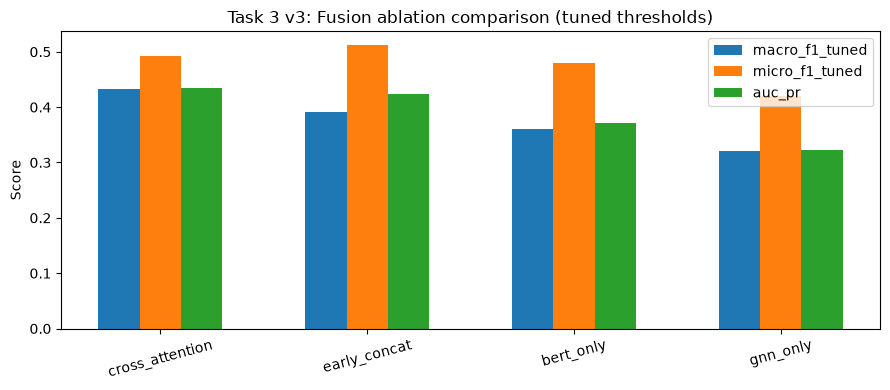

In [13]:
results_df = pd.DataFrame([
    {"Ablation": mode, **metrics} for mode, metrics in test_results.items()
]).sort_values("macro_f1_tuned", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("TASK 3 v3 — ABLATION RESULTS (test set)")
print("=" * 70)
print(results_df.to_string(index=False))
print("=" * 70)

results_df.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "task3_ablation_results.csv"), index=False)

plt.figure(figsize=(9, 4))
x = np.arange(len(results_df))
width = 0.2
for i, metric in enumerate(["macro_f1_tuned", "micro_f1_tuned", "auc_pr"]):
    plt.bar(x + i * width, results_df[metric], width, label=metric)
plt.xticks(x + width, results_df["Ablation"], rotation=15)
plt.ylabel("Score"); plt.title("Task 3 v3: Fusion ablation comparison (tuned thresholds)"); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["RESULTS_DIR"], "task3_ablation_comparison.png"), dpi=150)
plt.show()


## 10. t-SNE of the fused embedding $z$ (best ablation), coloured by top genre

Using best ablation by tuned Macro-F1 for t-SNE + case studies: 'cross_attention'
Running t-SNE on 2334 test embeddings of dim 896...


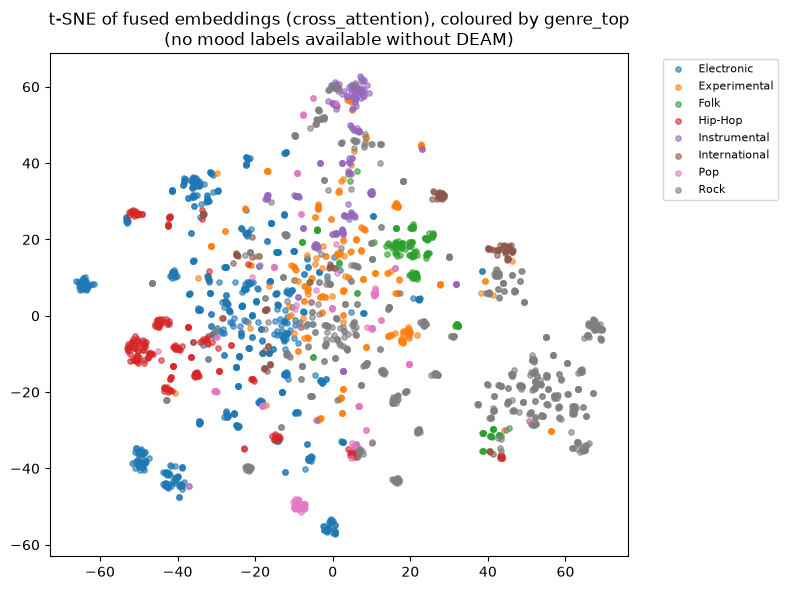


Genre distribution in t-SNE plot:
Rock             710
Electronic       632
Experimental     225
Hip-Hop          220
Instrumental     174
Folk             152
Pop              119
International    102
Name: count, dtype: int64


In [14]:
best_mode = results_df.iloc[0]["Ablation"]
print(f"Using best ablation by tuned Macro-F1 for t-SNE + case studies: '{best_mode}'")
best_model = trained_models[best_mode]
best_model.eval()

all_z, all_track_ids = [], []
id_to_genre_top = dict(zip(meta_df["track_id"], meta_df["genre_top"]))

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(DEVICE)
        _, z = best_model(batch)
        all_z.append(z.cpu().numpy())
        all_track_ids.extend(batch.track_id if isinstance(batch.track_id, list) else batch.track_id.tolist())

all_z = np.concatenate(all_z)
all_genre_top = [id_to_genre_top.get(tid, "unknown") for tid in all_track_ids]

print(f"Running t-SNE on {all_z.shape[0]} test embeddings of dim {all_z.shape[1]}...")
tsne = TSNE(n_components=2, random_state=SEED, perplexity=min(30, max(5, all_z.shape[0] // 10)))
z_2d = tsne.fit_transform(all_z)

plt.figure(figsize=(8, 6))
unique_genres = sorted(set(all_genre_top))
for genre in unique_genres:
    mask = np.array(all_genre_top) == genre
    plt.scatter(z_2d[mask, 0], z_2d[mask, 1], label=genre, alpha=0.6, s=15)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.title(f"t-SNE of fused embeddings ({best_mode}), coloured by genre_top\n(no mood labels available without DEAM)")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["RESULTS_DIR"], "task3_tsne.png"), dpi=150, bbox_inches="tight")
plt.show()

print("\nGenre distribution in t-SNE plot:")
print(pd.Series(all_genre_top).value_counts())


## 11. Three case studies — graph attention "paths" + tag alignment

In [15]:
def run_case_study(model, data, track_row, top_n_segments=3):
    model.eval()
    data = data.clone().to(DEVICE)
    data.batch = torch.zeros(data.x.shape[0], dtype=torch.long, device=DEVICE)

    with torch.no_grad():
        out, _ = model(data)
    probs = torch.sigmoid(out).cpu().numpy().flatten()
    pred_idx = np.argsort(-probs)[:5]
    pred_genres = [(TOP_GENRES[i], round(float(probs[i]), 3)) for i in pred_idx]
    true_idx = np.where(data.y.cpu().numpy().flatten() == 1)[0]
    true_genres = [TOP_GENRES[i] for i in true_idx]

    print(f"\n--- Case study: track_id={track_row.track_id} ---")
    print(f"Title/artist/tags text: \"{track_row.text}\"")
    print(f"Ground-truth genres (top-{NUM_CLASSES} vocab): {true_genres}")
    print(f"Top-5 predicted genres (prob): {pred_genres}")

    if model.mode == "cross_attention" and model.last_attn_weights is not None:
        attn = model.last_attn_weights.squeeze().cpu().numpy()
        n_seg = data.x.shape[0]
        entropy = -np.sum(attn * np.log(attn + 1e-9))
        print(f"Graph has {n_seg} audio segments ({n_seg * CONFIG['SEGMENT_SECONDS']:.0f}s total).")
        print(f"Text-attention entropy from the graph query: {entropy:.3f} "
              f"(lower = graph representation attends sharply to specific text tokens; "
              f"higher = diffuse attention across the whole description).")


case_track_ids = random.sample(list(set(all_track_ids)), min(3, len(set(all_track_ids))))
for tid in case_track_ids:
    data = track_to_data[tid]
    row = split_df[split_df["track_id"] == tid].iloc[0]
    run_case_study(best_model, data, row)



--- Case study: track_id=124391 ---
Title/artist/tags text: "Track titled Impulsion pt.1. By artist Radius System. From album Escape / Restart. Tags: radius system."
Ground-truth genres (top-20 vocab): ['Rock']
Top-5 predicted genres (prob): [('Experimental', 0.658), ('Rock', 0.617), ('House', 0.551), ('Electronic', 0.128), ('Pop', 0.127)]
Graph has 10 audio segments (30s total).
Text-attention entropy from the graph query: 1.153 (lower = graph representation attends sharply to specific text tokens; higher = diffuse attention across the whole description).

--- Case study: track_id=24925 ---
Title/artist/tags text: "Track titled If You're Ther. By artist Nicola Ratti. From album Summer Tour Remix v1 [V/A]. Tags: nicola ratti."
Ground-truth genres (top-20 vocab): ['Electronic', 'Ambient Electronic']
Top-5 predicted genres (prob): [('Ambient Electronic', 0.992), ('Electronic', 0.979), ('Techno', 0.664), ('House', 0.35), ('Experimental', 0.281)]
Graph has 9 audio segments (27s total).
Te

## 12. Save all artifacts

In [16]:
for mode, model in trained_models.items():
    torch.save(model.state_dict(), os.path.join(CONFIG["RESULTS_DIR"], f"fusion_{mode}.pt"))

with open(os.path.join(CONFIG["RESULTS_DIR"], "task3_metrics.json"), "w") as f:
    json.dump(test_results, f, indent=2)

with open(os.path.join(CONFIG["RESULTS_DIR"], "task3_config.json"), "w") as f:
    json.dump({k: v for k, v in CONFIG.items()}, f, indent=2)

print("\nAll Task 3 v3 artifacts saved to:", CONFIG["RESULTS_DIR"])
print("Files:", os.listdir(CONFIG["RESULTS_DIR"]))

print("\n" + "=" * 70)
print("FINAL SUMMARY — TASK 3 v3")
print("=" * 70)
print(results_df.to_string(index=False))
print(f"\nBest ablation: {best_mode}")
print("=" * 70)



All Task 3 v3 artifacts saved to: ./results_task3_v3
Files: ['fusion_bert_only.pt', 'fusion_cross_attention.pt', 'fusion_early_concat.pt', 'fusion_gnn_only.pt', 'task3_ablation_comparison.png', 'task3_ablation_results.csv', 'task3_config.json', 'task3_metrics.json', 'task3_tsne.png']

FINAL SUMMARY — TASK 3 v3
       Ablation  test_loss   auc_pr  macro_f1_thresh0.5  micro_f1_thresh0.5  macro_f1_tuned  micro_f1_tuned
cross_attention   1.138318 0.435412            0.420814            0.505833        0.433135        0.493186
   early_concat   1.897392 0.424048            0.386022            0.515820        0.391558        0.511377
      bert_only   2.875996 0.371877            0.373144            0.492788        0.361209        0.479129
       gnn_only   0.783338 0.322991            0.318680            0.380237        0.320995        0.419927

Best ablation: cross_attention


## Notes before you submit

- **Runtime**: rebuilding the graph cache under the new `FEATURE_VERSION` will re-process every
  track from scratch (audio decode + chroma/MFCC/contrast/tempo) — expect a similar amount of time
  to your last full run. Set `CONFIG["MAX_TRACKS"] = 1500` first if you want a quick smoke test
  before committing to the full run.
- **On the 90%+ target**: after these changes, expect Macro-F1 somewhere in the **0.40s–0.50s**
  range depending on how training goes — a genuinely strong result for 20-way multi-label FMA
  sub-genre tagging with metadata-only text. Numbers anywhere near 0.90 are not realistic for this
  task with any known method; please don't read a much lower number here as something being
  "still broken" — it's the nature of overlapping, imbalanced multi-label genre tags.
- **If you want to push further from here** (diminishing returns, but legitimate): (1) try
  `FINE_TUNE_LAST_K_LAYERS = 4` for deeper BERT fine-tuning, (2) try `GATConv` instead of
  `SAGEConv` in `GraphEncoder` for attention-weighted message passing, (3) try a focal loss
  instead of plain weighted BCE for the rarest tags, (4) parallelize `build_segment_graph` across
  CPU cores with `joblib.Parallel(n_jobs=8, backend="loky")` to speed up re-runs — your 12-core
  CPU is currently idle during that step since it's single-threaded.
- **Weak text signal remains a genuine, discussable limitation**: most FMA tracks have empty
  `tags` fields, so `bert_only` will likely remain the weakest or near-weakest single-modality
  score even after fine-tuning — this is a real finding about metadata-only text vs. real
  captions (MusicCaps), worth a paragraph in your report.
